In [8]:
import numpy as np
import netCDF4 as nc
import matplotlib.pyplot as plt
import glob

# 获取当前目录下的所有 .txt 文件
file_list = glob.glob('.\Data\original\*.nc')

In [9]:
test1_ds=nc.Dataset('.\Data\original\dt_global_twosat_phy_l4_19930101_vDT2021.nc')
test1_ds.variables.keys()


dict_keys(['crs', 'time', 'latitude', 'lat_bnds', 'longitude', 'lon_bnds', 'nv', 'sla', 'err_sla', 'ugosa', 'err_ugosa', 'vgosa', 'err_vgosa', 'adt', 'ugos', 'vgos', 'tpa_correction', 'flag_ice'])

In [26]:
np.array(test1_ds.variables['latitude'][:])

array([-89.875, -89.625, -89.375, -89.125, -88.875, -88.625, -88.375,
       -88.125, -87.875, -87.625, -87.375, -87.125, -86.875, -86.625,
       -86.375, -86.125, -85.875, -85.625, -85.375, -85.125, -84.875,
       -84.625, -84.375, -84.125, -83.875, -83.625, -83.375, -83.125,
       -82.875, -82.625, -82.375, -82.125, -81.875, -81.625, -81.375,
       -81.125, -80.875, -80.625, -80.375, -80.125, -79.875, -79.625,
       -79.375, -79.125, -78.875, -78.625, -78.375, -78.125, -77.875,
       -77.625, -77.375, -77.125, -76.875, -76.625, -76.375, -76.125,
       -75.875, -75.625, -75.375, -75.125, -74.875, -74.625, -74.375,
       -74.125, -73.875, -73.625, -73.375, -73.125, -72.875, -72.625,
       -72.375, -72.125, -71.875, -71.625, -71.375, -71.125, -70.875,
       -70.625, -70.375, -70.125, -69.875, -69.625, -69.375, -69.125,
       -68.875, -68.625, -68.375, -68.125, -67.875, -67.625, -67.375,
       -67.125, -66.875, -66.625, -66.375, -66.125, -65.875, -65.625,
       -65.375, -65.

In [27]:
np.array(test1_ds.variables['longitude'][:])

array([-179.875, -179.625, -179.375, ...,  179.375,  179.625,  179.875],
      dtype=float32)

In [28]:
for i in test1_ds.variables.keys():
    print(i,end='|')
    if i in ['crs','lat_bnds','lon_bnds']:
        print()
        continue
    else:
        print(f"{test1_ds[i].name}:{test1_ds[i].long_name}")

crs|
time|time:Time
latitude|latitude:Latitude
lat_bnds|
longitude|longitude:Longitude
lon_bnds|
nv|nv:Number of cell vertices
sla|sla:Sea level anomaly
err_sla|err_sla:Formal mapping error
ugosa|ugosa:Geostrophic velocity anomalies: zonal component
err_ugosa|err_ugosa:Formal mapping error on zonal geostrophic velocity anomalies
vgosa|vgosa:Geostrophic velocity anomalies: meridian component
err_vgosa|err_vgosa:Formal mapping error on meridional geostrophic velocity anomalies
adt|adt:Absolute dynamic topography
ugos|ugos:Absolute geostrophic velocity: zonal component
vgos|vgos:Absolute geostrophic velocity: meridian component
tpa_correction|tpa_correction:TOPEX-A instrumental drift correction derived from altimetry and tide gauges global comparisons (WCRP Sea Level Budget Group, 2018)
flag_ice|flag_ice:Ice Flag for a 15% criterion of ice concentration


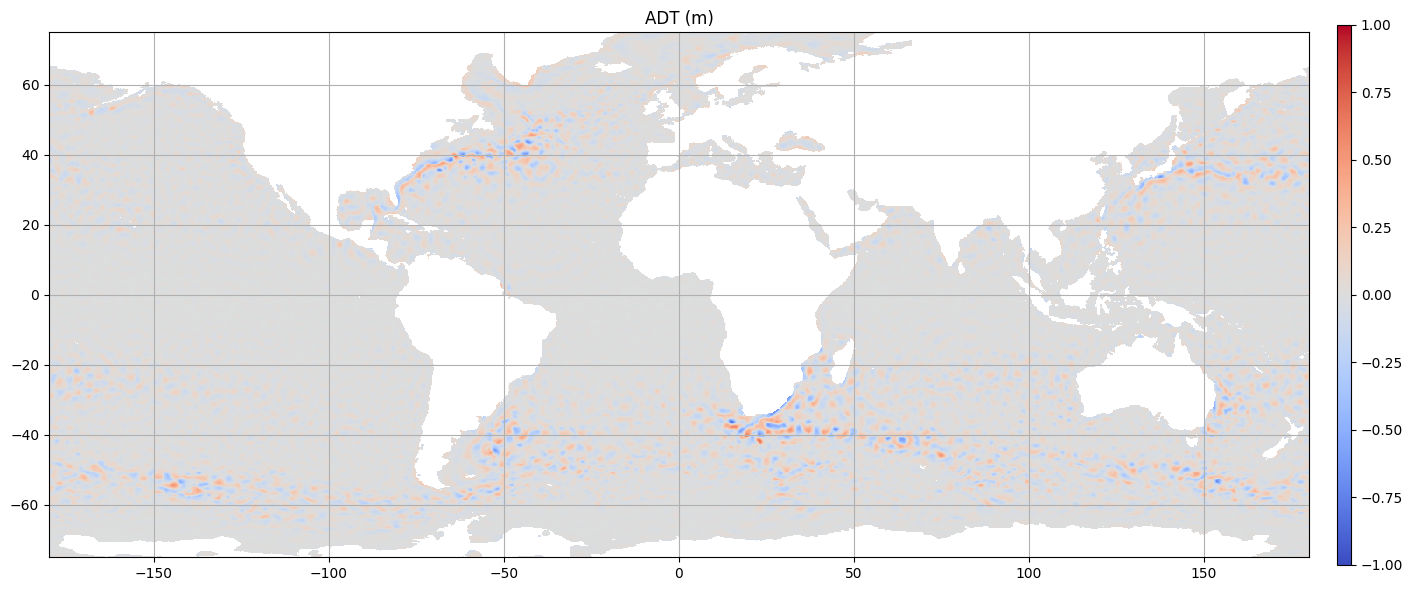

In [32]:
from matplotlib import pyplot as plt

fig = plt.figure(figsize=(14, 12))
ax = fig.add_axes([0.02, 0.51, 0.9, 0.45])
ax.set_title("ADT (m)")
ax.set_ylim(-75, 75)
ax.set_aspect("equal")
m = h.display(ax, name="adt", vmin=-1, vmax=1)
ax.grid(True)
plt.colorbar(m, cax=fig.add_axes([0.94, 0.51, 0.01, 0.45]))

In [40]:
from py_eddy_tracker import start_logger

start_logger().setLevel("DEBUG")  # Available options: ERROR, WARNING, INFO, DEBUG
from datetime import datetime
from py_eddy_tracker.dataset.grid import RegularGridDataset
h = RegularGridDataset('Data\original\dt_global_twosat_phy_l4_19930101_vDT2021.nc',"longitude", "latitude")
h.bessel_high_filter("adt", 500, order=3)
date = datetime(1991, 1, 1)
a, c = h.eddy_identification(
    "adt",
    "ugos",
    "vgos",  # Variables used for identification
    date,  # Date of identification
    0.002,  # step between two isolines of detection (m)
    pixel_limit=(5, 2000),  # Min and max pixel count for valid contour
    shape_error=55,  # Error max (%) between ratio of circle fit and contour
)

WARNING 2024-04-24 17:08:33,396 grid.__init__ :
	We assume pixel position of grid is centered for Data\original\dt_global_twosat_phy_l4_19930101_vDT2021.nc
	DEBUG 2024-04-24 17:08:33,397 	grid.	load_general_features :
		Load general feature from Data\original\dt_global_twosat_phy_l4_19930101_vDT2021.nc
	DEBUG 2024-04-24 17:08:33,413 	grid.	bessel_high_filter :
		Run filtering with wavelength of 500 km and order of 3 ...
WARNING 2024-04-24 17:08:33,413 grid.convolve_filter_with_dynamic_kernel :
	No filtering above 85.000000 degrees of latitude
	DEBUG 2024-04-24 17:08:33,413 	grid.	grid :
		Load adt from Data\original\dt_global_twosat_phy_l4_19930101_vDT2021.nc


	DEBUG 2024-04-24 17:08:43,911 	grid.	bessel_high_filter :
		Filtering done
	DEBUG 2024-04-24 17:08:43,920 	grid.	grid :
		Load ugos from Data\original\dt_global_twosat_phy_l4_19930101_vDT2021.nc
	DEBUG 2024-04-24 17:08:43,953 	grid.	grid :
		Load vgos from Data\original\dt_global_twosat_phy_l4_19930101_vDT2021.nc


Remain  0:00:00.610920 ETA  2024-04-24 17:08:44.485009 current kernel size : (847, 108) Step : 690/720    


INFO 2024-04-24 17:08:44,120 grid.eddy_identification :
	We will apply on step a factor to be coherent with grid : 1.000000
c:\Users\yuhanxue\anaconda3\envs\pynb\lib\site-packages\numpy\lib\function_base.py:4650: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  arr.partition(
	DEBUG 2024-04-24 17:08:44,144 	grid.	eddy_identification :
		Levels from -0.853003 to 0.684198
INFO 2024-04-24 17:08:44,144 eddy_feature.__init__ :
	Start computing iso lines
	DEBUG 2024-04-24 17:08:44,154 	eddy_feature.	__init__ :
		wrapping activated to compute contour
	DEBUG 2024-04-24 17:08:44,154 	eddy_feature.	__init__ :
		X shape : (1441,)
	DEBUG 2024-04-24 17:08:44,154 	eddy_feature.	__init__ :
		Y shape : (720,)
	DEBUG 2024-04-24 17:08:44,154 	eddy_feature.	__init__ :
		Z shape : (1441, 720)
INFO 2024-04-24 17:08:44,154 eddy_feature.__init__ :
	Start computing iso lines with 771 levels from -0.854000 to 0.686000 ...
INFO 2024-04-24 17:08:51,205 eddy_feature.find_wrapcut_path

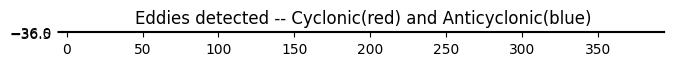

In [25]:
fig = plt.figure()
ax = fig.add_axes([0.03, 0.03, 0.94, 0.94])
ax.set_title("Eddies detected -- Cyclonic(red) and Anticyclonic(blue)")
# ax.set_ylim(-75, 75)
# ax.set_xlim(0, 360)
ax.set_aspect("equal")
a.display(ax, color="b", linewidth=0.5)
c.display(ax, color="r", linewidth=0.5)
ax.grid()
# fig.savefig("share/png/eddies.png")

In [35]:
date = datetime(1991, 1, 1)

In [37]:
date.strftime("%Y%m%dT%H%M%S.nc")


'19910101T000000.nc'